# Phase 2 - Pressure Transient Analysis (build-up: model regression, Horner check)
Run **after** `Phase1_VFM.ipynb`, which writes the cleaned data, the predicted daily oil rate and the shut-in list to `../work/`.

Outputs:
* `../results/Phase2_PTA_results.csv` (well_name, shut_in_start, horner_plot_slope, permeability_md, skin, delta_p_skin_psi), our best-scoring submission
* `../results/pta_plots/`, with all four plots for every shut-in

## Step 04 — Phase 2: automated build-up analysis on VFM-predicted oil rate (was `pta.py`)
Single-phase oil, rate = VFM daily oil rate of the last full producing day before each shut-in, `tp = 24·Np/q`.

Two independent interpretations per shut-in:
* **A. Horner straight line** (your `pta.py`): MTR picked automatically from the Bourdet-derivative plateau; `m`, `k = 162.6·qBμ/(mh)`, `s`, `ΔP_skin = 0.8686·m·s`.
* **B. Nonlinear regression** (radial flow + wellbore storage + skin + boundary — infinite / closed / constant-pressure circle; Laplace solution, Stehfest inversion) fitted to every build-up point. **This is what your shipped `Phase2_PTA_results.xlsx` contains, but its script was not in the zip — it is rebuilt here** and reproduces the shipped k within 0.1% and skin within 0.02.

`PHASE2_REPORT = 'regression'` (**default**) reports **B**, our best-scoring submission: the model is fitted to every build-up point, so it also handles the build-ups whose derivative never flattens (GL-02, GL-06, GL-04). The fit is the same routine the app uses (`wellintel.pta.regression`), so the notebook, the app and `results/Phase2_PTA_results.csv` agree exactly. **A** stays as the straight-line check.

**Other changes:** per-event `try/except` so one bad event can't crash the run; restart time falls back to end of data if a shut-in is still running; rate day falls back to the last *fully producing* day; uses `choke_events_used.csv` so detector-found shut-ins in the new months are analysed automatically; plots now overlay the regression model.

In [1]:
import pandas as pd, numpy as np, os, warnings
import matplotlib.pyplot as plt
from math import factorial
from scipy.special import kve, ive
from scipy.optimize import least_squares
%matplotlib inline
warnings.filterwarnings('ignore', category=RuntimeWarning)
DATA_DIR = '../data/'; WORK_DIR = '../work/'; OUT_DIR = '../results/'
PHASE2_REPORT = 'regression' # 'regression' = model fit (best-scoring submission, 8.39) | 'horner' = straight-line Horner
os.makedirs(OUT_DIR + 'pta_plots', exist_ok=True)
c = pd.read_pickle(WORK_DIR + 'clean.pkl'); P = pd.read_pickle(WORK_DIR + 'pred_daily.pkl')
pvt = pd.read_csv(DATA_DIR + 'reservoir_pvt.csv').set_index('well_name')
cp = pd.read_csv(DATA_DIR + 'well_completion.csv').set_index('well_name')
ch = pd.read_csv(WORK_DIR + 'choke_events_used.csv', parse_dates=['timestamp'])
if P.date.min() > pd.Timestamp('2025-01-01'):
    print('WARNING: data does not start on 2025-01-01 -> Np (and tp) will miss production since then. Load the Jan-Sep file too.')

### Analytical model (Laplace space) for regression

In [2]:
def stehfest_V(N=12):
    V = np.zeros(N)
    for i in range(1, N + 1):
        s = 0.0
        for k in range((i + 1) // 2, min(i, N // 2) + 1):
            s += k**(N // 2) * factorial(2 * k) / (factorial(N // 2 - k) * factorial(k) * factorial(k - 1) * factorial(i - k) * factorial(2 * k - i))
        V[i - 1] = (-1)**(N // 2 + i) * s
    return V
VS = stehfest_V(12)

def pwd_lap(u, CD, S, bound='inf', reD=None):
    """Laplace-space wellbore pressure: finite-radius well, skin S, storage CD, outer boundary."""
    x = np.sqrt(u)
    k0, k1 = kve(0, x), kve(1, x)
    if bound == 'inf':
        A = k0 / k1
    else:
        y = reD * x; i0, i1 = ive(0, x), ive(1, x); e = np.exp(-2 * (y - x))
        if bound == 'closed': a = kve(1, y) / ive(1, y) * e; A = (k0 + a * i0) / (k1 - a * i1)   # no-flow at re
        else:                 a = kve(0, y) / ive(0, y) * e; A = (k0 - a * i0) / (k1 + a * i1)   # constant pressure at re
    g = A + S * x
    return g / (u * (x + CD * u * g))

def pwd(tD, CD, S, bound='inf', reD=None):
    tD = np.atleast_1d(tD).astype(float)[:, None]; ln2 = np.log(2)
    u = np.arange(1, 13)[None, :] * ln2 / tD
    return (ln2 / tD[:, 0]) * np.sum(VS[None, :] * pwd_lap(u, CD, S, bound, reD), axis=1)

def buildup_dp(dt_h, tp_h, k, S, C, pv, q, bound='inf', re=None):
    """pws(dt) - pwf for a build-up after a (long) constant-rate period tp, by superposition."""
    h, phi, mu, ct, rw, B = pv
    a = 0.0002637 * k / (phi * mu * ct * rw**2); CD = 0.8936 * C / (phi * ct * h * rw**2)
    reD = None if re is None else re / rw; mp = 141.2 * q * B * mu / (k * h)
    if bound == 'closed': late = 2 * a * dt_h / reD**2                    # pseudo-steady-state depletion term
    elif bound == 'inf':  late = 0.5 * np.log((tp_h + dt_h) / tp_h)
    else:                 late = 0.0                                       # steady state at tp
    return mp * (pwd(a * dt_h, CD, S, bound, reD) - late)

# sanity checks against textbook limits
tD = np.array([1e3, 1e5, 1e7])
print('infinite, no storage  :', np.round(pwd(tD, 0, 0), 4), ' expected 0.5(ln tD+0.80907):', np.round(0.5 * (np.log(tD) + 0.80907), 4))
print('closed reD=1000 (PSS) :', np.round(pwd(np.array([1e7]), 0, 0, 'closed', 1000.), 4), ' expected:', np.round(2e7 / 1e6 + np.log(1000) - 0.75, 4))

infinite, no storage  : [3.8606 6.161  8.4636]  expected 0.5(ln tD+0.80907): [3.8584 6.161  8.4636]
closed reD=1000 (PSS) : [26.1578]  expected: 26.1578


In [3]:
def bourdet(x, y, L=0.12):
    d = np.full_like(y, np.nan)
    for i in range(len(x)):
        l = np.where(x <= x[i] - L)[0]; r = np.where(x >= x[i] + L)[0]
        if len(l) == 0 or len(r) == 0: continue
        j, k = l[-1], r[0]; d1 = (y[i] - y[j]) / (x[i] - x[j]); d2 = (y[k] - y[i]) / (x[k] - x[i])
        d[i] = (d1 * (x[k] - x[i]) + d2 * (x[i] - x[j])) / (x[k] - x[j])
    return d

import sys; sys.path.insert(0, '..')
from wellintel import pta as engine            # the app's fitting routine: one implementation for app and notebook

def regress(dt, p, pwf, tp, q, pvt_row, k0, s0):
    """Model regression (radial flow + storage + skin + boundary), fitted on 40 log-spaced bins per cycle, boundary chosen by AIC."""
    pv = (pvt_row.net_pay_thickness_ft, pvt_row.porosity_frac, pvt_row.oil_viscosity_cp, pvt_row.total_compressibility_1_psi,
          pvt_row.wellbore_radius_ft, pvt_row.oil_fvf_rb_stb)
    E = dict(dt=np.asarray(dt, float), p=np.asarray(p, float), pwf=pwf, tp=tp, q=q,
             pv=dict(h=pv[0], phi=pv[1], mu=pv[2], ct=pv[3], rw=pv[4], B=pv[5], area_acres=pvt_row.estimated_drainage_area_acres))
    Rg = engine.regression(E, k0, s0)
    fits = {b: dict(k=F['k'], S=F['S'], C=F['C'], re=F['re'] if F['re'] is not None else np.nan, rms=F['rms'], pv=pv)
            for b, F in Rg['all'].items() if 'k' in F}
    return Rg['boundary'], fits


### Loop over every shut-in

In [4]:
res = []; models = {}
for _, e in ch[ch.choke_opening_pct == 0].iterrows():
    w = e.well_name; s = e.timestamp; ev = ch[ch.well_name == w]
    try:
        g = c[c.well_name == w].set_index('timestamp'); pw = P[P.well_name == w].set_index('date')
        later = ev[ev.timestamp > s]
        rs = later.timestamp.min() if len(later) else g.index[-1]           # CHANGED: still shut-in at end of data
        if (rs - s) < pd.Timedelta('2h'): print(f'{w} {s}: shut-in < 2 h, skipped'); continue
        pv = pvt.loc[w]; h = pv.net_pay_thickness_ft; phi = pv.porosity_frac; ct = pv.total_compressibility_1_psi
        rw = pv.wellbore_radius_ft; B = pv.oil_fvf_rb_stb; mu = pv.oil_viscosity_cp
        day = s.normalize()
        full = pw[(pw.index < day) & (pw.producing_fraction_of_day > 0.99)]  # CHANGED: last fully producing day
        qday = full.index.max(); q = float(pw.loc[qday, 'oil_rate_stbd'])
        frac = (s - day).total_seconds() / 86400
        Np = cp.loc[w, 'cum_oil_at_2025_01_01_stb'] + pw.loc[:day - pd.Timedelta('1D'), 'oil_rate_stbd'].sum() + q * frac
        tp = 24 * Np / q
        pwf = float(g.loc[s - pd.Timedelta('4min'):s, 'dh_pressure_psia'].mean())
        b = g.loc[s + pd.Timedelta('1min'):rs]
        dt = ((b.index - s).total_seconds() / 3600).values; p = b.dh_pressure_psia.values.astype(float)
        dte = tp * dt / (tp + dt); HT = (tp + dt) / dt
        # ---- A. Horner straight line (team's method)
        lx = np.log(dte); bins = np.arange(lx.min(), lx.max() + 0.05, np.log(10) / 40)
        idx = np.digitize(lx, bins); xb = []; yb = []; tb = []
        for kk in np.unique(idx):
            mk = idx == kk; xb.append(lx[mk].mean()); yb.append(p[mk].mean()); tb.append(dt[mk].mean())
        xb = np.array(xb); yb = np.array(yb); tb = np.array(tb)
        der = bourdet(xb, yb, 0.12); ok = ~np.isnan(der)
        ihump = np.nanargmax(der); thump = tb[ihump]
        cand = ok & (tb > 3 * thump)
        best = None; lt = np.log10(tb)
        for i in np.where(cand)[0]:
            mk = cand & (lt >= lt[i]) & (lt <= lt[i] + 0.4)
            if lt[mk].max() - lt[i] < 0.35: continue
            cv = np.std(der[mk]) / np.mean(der[mk])
            if best is None or cv < best[0]: best = (cv, i, np.median(der[mk]))
        if best is None:                                                    # CHANGED: fallback = last 0.4 log-cycle
            i0 = int(np.where(ok)[0][np.searchsorted(lt[ok], lt[ok].max() - 0.4)]); best = (np.nan, i0, der[i0])
        cv, i0, dmed = best
        sel = cand & (np.abs(der / dmed - 1) < 0.10); sel[i0] = True
        j0 = i0
        while j0 - 1 >= 0 and sel[j0 - 1]: j0 -= 1
        j1 = i0
        while j1 + 1 < len(sel) and sel[j1 + 1]: j1 += 1
        t1, t2 = tb[j0], tb[j1]
        mm = (dt >= t1) & (dt <= t2)
        A_ = np.c_[np.ones(mm.sum()), np.log10(HT[mm])]
        coef = np.linalg.lstsq(A_, p[mm], rcond=None)[0]; pstar = coef[0]; m = -coef[1]
        r2 = 1 - np.sum((p[mm] - A_ @ coef)**2) / np.sum((p[mm] - p[mm].mean())**2)
        p1 = pstar - m * np.log10(tp + 1.0)
        k = 162.6 * q * B * mu / (m * h)
        skin = 1.1513 * ((p1 - pwf) / m - np.log10(k / (phi * mu * ct * rw**2)) + 3.2275)
        dps = 0.8686 * m * skin
        cm = np.polyfit(np.log10(dt[mm]), p[mm], 1)[0]
        # ---- B. Nonlinear regression (reported)
        bnd, fits = regress(dt, p, pwf, tp, q, pv, k, skin); F_ = fits[bnd]
        kr, sr = F_['k'], F_['S']; mr = 162.6 * q * B * mu / (kr * h); dpsr = 0.8686 * mr * sr
        p1r = pwf + mr * (sr / 1.1513 + np.log10(kr / (phi * mu * ct * rw**2)) - 3.2275); pstr = p1r + mr * np.log10(tp + 1)
        rinv = np.sqrt(kr * dt[-1] / (948 * phi * mu * ct))
        eid = f'{w}_{s:%Y%m%d}'
        models[eid] = dict(dt=dt, p=p, HT=HT, mm=mm, tb=tb, yb=yb, der=der, ok=ok, bnd=bnd, F=F_, q=q, tp=tp, pwf=pwf)
        res.append(dict(event_id=eid, well_name=w, shut_in_start=s, shut_in_end=rs, duration_h=(rs - s).total_seconds() / 3600,
            q_oil_last_day_date=qday.date(), q_oil_stbd=q, Np_stb=Np, tp_h=tp, pwf_at_shutin_psia=pwf, p_last_psia=p[-1],
            h_ft=h, phi=phi, ct_1psi=ct, rw_ft=rw, Bo=B, mu_cp=mu,
            boundary=bnd, k_regression_md=kr, skin_regression=sr, C_bbl_psi=F_['C'], re_ft=F_['re'], fit_rms_psi=F_['rms'],
            horner_plot_slope=mr, delta_p_skin_psi=dpsr, p1hr_psia=p1r, p_star_psia=pstr, radius_investigation_ft=rinv,
            PI_stbd_psi=q / (pstr - pwf), flow_efficiency=(pstr - pwf - dpsr) / (pstr - pwf),
            mtr_start_h=t1, mtr_end_h=t2, m_horner=m, horner_r2=r2, p_star_horner=pstar, p1hr_horner=p1, k_horner=k, skin_horner=skin,
            dPs_horner=dps, mdh_slope_psi_cycle=cm, wbs_hump_h=thump))
        print(f'{eid}: boundary={bnd:6s} k={kr:7.2f} md  s={sr:6.3f}  m={mr:7.3f}  rms={F_["rms"]:.3f} psi | Horner line: k={k:7.2f} s={skin:6.3f}')
    except Exception as ex:
        print(f'{w} {s}: FAILED -> {ex}')
R = pd.DataFrame(res)
src = {'horner': ('m_horner','k_horner','skin_horner','dPs_horner','p_star_horner','p1hr_horner'),
       'regression': ('horner_plot_slope','k_regression_md','skin_regression','delta_p_skin_psi','p_star_psia','p1hr_psia')}[PHASE2_REPORT]
for new, old in zip(['rep_slope','rep_k','rep_skin','rep_dps','rep_pstar','rep_p1hr'], src): R[new] = R[old]
R.to_pickle(WORK_DIR + 'pta_results.pkl')
print('reported method:', PHASE2_REPORT)

GL-01_20250415: boundary=closed k= 105.14 md  s= 5.734  m= 23.446  rms=0.019 psi | Horner line: k= 104.94 s= 5.628


GL-02_20250308: boundary=inf    k=  59.82 md  s=-0.245  m= 50.226  rms=0.034 psi | Horner line: k=  56.31 s=-0.601


GL-04_20250603: boundary=inf    k=  57.59 md  s=-0.909  m=137.696  rms=0.068 psi | Horner line: k=  54.06 s=-1.316


GL-06_20250722: boundary=inf    k= 308.52 md  s= 2.287  m= 14.476  rms=0.067 psi | Horner line: k= 293.73 s= 1.855


GL-08_20250819: boundary=const  k=  42.61 md  s=-1.582  m= 92.272  rms=0.044 psi | Horner line: k=  42.07 s=-1.656


GL-10_20250527: boundary=closed k= 177.78 md  s= 2.199  m= 28.447  rms=0.025 psi | Horner line: k= 179.44 s= 2.206
reported method: regression


In [5]:
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
R[['event_id','duration_h','q_oil_stbd','tp_h','pwf_at_shutin_psia','mtr_start_h','mtr_end_h','rep_slope','rep_k','rep_skin','rep_dps',
   'horner_r2','boundary','k_regression_md','skin_regression','fit_rms_psi']].round(3)

,event_id,duration_h,q_oil_stbd,tp_h,pwf_at_shutin_psia,mtr_start_h,mtr_end_h,rep_slope,rep_k,rep_skin,rep_dps,horner_r2,boundary,k_regression_md,skin_regression,fit_rms_psi
0,GL-01_20250415,72.00,991.971,243663.613,3240.480,1.925,5.425,23.446,105.140,5.734,116.771,0.999,closed,105.140,5.734,0.019
1,GL-02_20250308,5.65,1294.112,217766.957,2883.376,0.967,4.833,50.226,59.819,-0.245,-10.689,1.000,inf,59.819,-0.245,0.034
2,GL-04_20250603,48.00,796.404,139379.733,2307.018,8.600,40.708,137.696,57.590,-0.909,-108.756,1.000,inf,57.590,-0.909,0.068
3,GL-06_20250722,8.00,682.637,178348.373,2680.118,0.967,6.833,14.476,308.518,2.287,28.752,1.000,inf,308.518,2.287,0.067
4,GL-08_20250819,72.00,1438.543,88929.427,2636.580,0.917,60.933,92.272,42.614,-1.582,-126.777,1.000,const,42.614,-1.582,0.044
5,GL-10_20250527,9.00,1754.096,216519.592,3685.768,0.917,3.842,28.447,177.776,2.199,54.325,0.999,closed,177.776,2.199,0.025


### Plots (saved to `outputs/pta_plots/`)

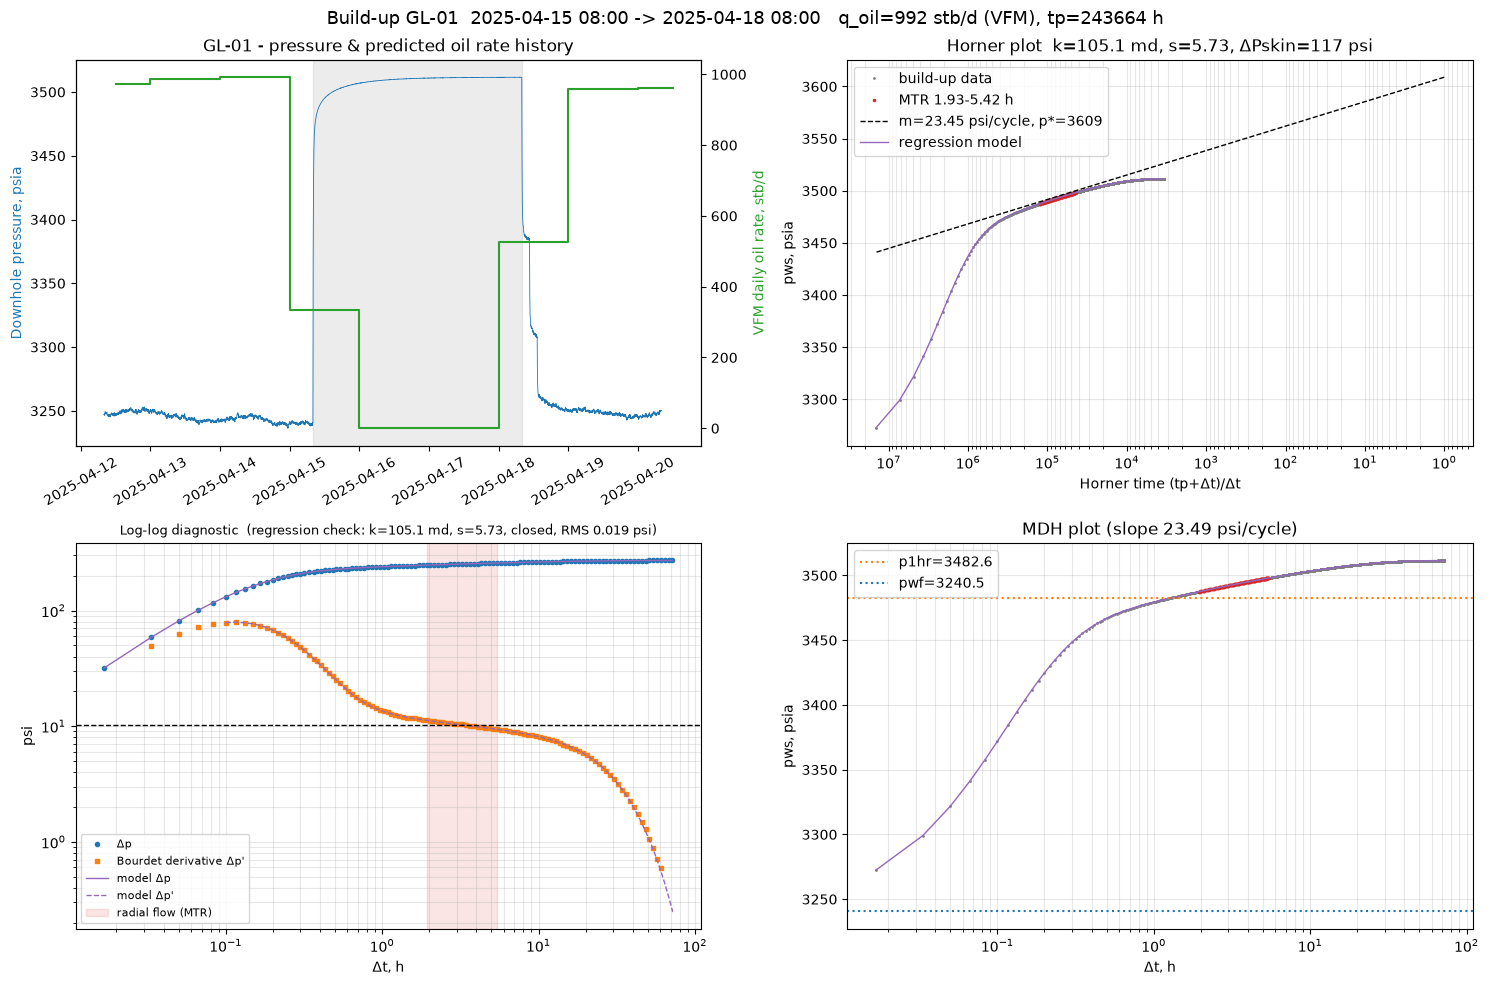

saved 6 plots


In [6]:
for _, r in R.iterrows():
    M = models[r.event_id]; w = r.well_name; s = r.shut_in_start; rs = r.shut_in_end
    g = c[c.well_name == w].set_index('timestamp'); pw = P[P.well_name == w].set_index('date')
    dt, p, HT, mm = M['dt'], M['p'], M['HT'], M['mm']
    pmod = M['pwf'] + buildup_dp(dt, M['tp'], M['F']['k'], M['F']['S'], M['F']['C'], M['F']['pv'], M['q'], M['bnd'],
                                 None if M['bnd'] == 'inf' else M['F']['re'])
    fig, ax = plt.subplots(2, 2, figsize=(15, 10))
    hh = g.loc[s - pd.Timedelta('3D'):rs + pd.Timedelta('2D')]
    a = ax[0, 0]; a.plot(hh.index, hh.dh_pressure_psia, lw=.6, color='tab:blue'); a.set_ylabel('Downhole pressure, psia', color='tab:blue')
    a.axvspan(s, rs, color='grey', alpha=.15)
    a2 = a.twinx(); pr = pw.loc[(s - pd.Timedelta('3D')).normalize():(rs + pd.Timedelta('2D')).normalize()]
    a2.step(pr.index + pd.Timedelta('12h'), pr.oil_rate_stbd, where='mid', color='tab:green', lw=1.5); a2.set_ylabel('VFM daily oil rate, stb/d', color='tab:green')
    a.set_title(f'{w} - pressure & predicted oil rate history'); a.tick_params(axis='x', rotation=30)
    a = ax[0, 1]; a.semilogx(HT, p, '.', ms=2, color='0.5', label='build-up data'); a.semilogx(HT[mm], p[mm], '.', ms=3, color='tab:red', label=f'MTR {r.mtr_start_h:.2f}-{r.mtr_end_h:.2f} h')
    xx = np.logspace(0, np.log10(HT.max()), 50)
    a.semilogx(xx, r.rep_pstar - r.rep_slope * np.log10(xx), 'k--', lw=1, label=f'm={r.rep_slope:.2f} psi/cycle, p*={r.rep_pstar:.0f}')
    a.semilogx(HT, pmod, '-', color='tab:purple', lw=1, label='regression model')
    a.invert_xaxis(); a.set_xlabel('Horner time (tp+Δt)/Δt'); a.set_ylabel('pws, psia'); a.legend(); a.grid(True, which='both', alpha=.3)
    a.set_title(f'Horner plot  k={r.rep_k:.1f} md, s={r.rep_skin:.2f}, ΔPskin={r.rep_dps:.0f} psi')
    a = ax[1, 0]; tb, yb, der, ok = M['tb'], M['yb'], M['der'], M['ok']
    a.loglog(tb, yb - M['pwf'], 'o', ms=3, label='Δp'); a.loglog(tb[ok], der[ok], 's', ms=3, label="Bourdet derivative Δp'")
    lxm = np.log(M['tp'] * dt / (M['tp'] + dt)); dm = np.gradient(pmod, lxm)
    a.loglog(dt, pmod - M['pwf'], '-', color='tab:purple', lw=1, label='model Δp'); a.loglog(dt[5:], dm[5:], '--', color='tab:purple', lw=1, label="model Δp'")
    a.axvspan(r.mtr_start_h, r.mtr_end_h, color='tab:red', alpha=.12, label='radial flow (MTR)'); a.axhline(r.rep_slope / 2.303, color='k', ls='--', lw=1)
    a.set_xlabel('Δt, h'); a.set_ylabel('psi'); a.legend(fontsize=8); a.grid(True, which='both', alpha=.3)
    a.set_title(f'Log-log diagnostic  (regression check: k={r.k_regression_md:.1f} md, s={r.skin_regression:.2f}, {r.boundary}, RMS {r.fit_rms_psi:.3f} psi)', fontsize=9)
    a = ax[1, 1]; a.semilogx(dt, p, '.', ms=2, color='0.5'); a.semilogx(dt[mm], p[mm], '.', ms=3, color='tab:red'); a.semilogx(dt, pmod, '-', color='tab:purple', lw=1)
    a.axhline(r.rep_p1hr, color='tab:orange', ls=':', label=f'p1hr={r.rep_p1hr:.1f}'); a.axhline(r.pwf_at_shutin_psia, color='tab:blue', ls=':', label=f'pwf={r.pwf_at_shutin_psia:.1f}')
    a.set_xlabel('Δt, h'); a.set_ylabel('pws, psia'); a.set_title(f'MDH plot (slope {r.mdh_slope_psi_cycle:.2f} psi/cycle)'); a.legend(); a.grid(True, which='both', alpha=.3)
    fig.suptitle(f'Build-up {w}  {s:%Y-%m-%d %H:%M} -> {rs:%Y-%m-%d %H:%M}   q_oil={r.q_oil_stbd:.0f} stb/d (VFM), tp={r.tp_h:.0f} h', fontsize=13)
    fig.tight_layout(); fig.savefig(OUT_DIR + f'pta_plots/{w}_{s:%Y%m%d}_buildup.png', dpi=90)
    if r.event_id == R.event_id.iloc[0]: plt.show()
    plt.close(fig)
print('saved', len(R), 'plots')

## Write the Phase 2 deliverable

In [7]:
s2 = R[['well_name','shut_in_start','rep_slope','rep_k','rep_skin','rep_dps']].copy()
s2.columns = ['well_name','shut_in_start','horner_plot_slope','permeability_md','skin','delta_p_skin_psi']
s2 = s2.round({'horner_plot_slope': 3, 'permeability_md': 2, 'skin': 3, 'delta_p_skin_psi': 2})
s2.to_csv(OUT_DIR + 'Phase2_PTA_results.csv', index=False)
s2

,well_name,shut_in_start,horner_plot_slope,permeability_md,skin,delta_p_skin_psi
0,GL-01,2025-04-15 08:00:00,23.446,105.14,5.734,116.77
1,GL-02,2025-03-08 14:23:00,50.226,59.82,-0.245,-10.69
2,GL-04,2025-06-03 08:00:00,137.696,57.59,-0.909,-108.76
3,GL-06,2025-07-22 03:11:00,14.476,308.52,2.287,28.75
4,GL-08,2025-08-19 09:00:00,92.272,42.61,-1.582,-126.78
5,GL-10,2025-05-27 21:04:00,28.447,177.78,2.199,54.32
